In [1]:
import os, re
os.chdir("..")  # run from the project root so paths work
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_parquet("data/processed/train_merged.parquet")
print(df.shape, f"{df.memory_usage(deep=True).sum()/1e9:.2f} GB")
print(df["has_identity"].value_counts(normalize=True))

(590540, 435) 0.97 GB
has_identity
0    0.755761
1    0.244239
Name: proportion, dtype: float64


In [2]:
def group_of(c):
    rules = [(r"^V\d+$", "V"), (r"^C\d+$", "C"), (r"^D\d+$", "D"), (r"^M\d+$", "M"),
             (r"^id_\d+$", "id"), (r"^card\d$", "card"), (r"^addr\d$", "addr"),
             (r"^dist\d$", "dist"), (r"_emaildomain$", "email"), (r"^Device", "device")]
    for pat, name in rules:
        if re.search(pat, c):
            return name
    return "core"

miss = df.isna().mean().rename("na_rate").to_frame()
miss["group"] = [group_of(c) for c in miss.index]
summary = miss.groupby("group")["na_rate"].agg(["count", "mean", "min", "max"])
print(summary.sort_values("mean").round(3))

        count   mean    min    max
group                             
C          14  0.000  0.000  0.000
core        6  0.000  0.000  0.000
card        6  0.005  0.000  0.015
addr        2  0.111  0.111  0.111
V         339  0.430  0.000  0.861
email       2  0.464  0.160  0.768
M           9  0.499  0.287  0.593
D          15  0.582  0.002  0.934
dist        2  0.766  0.597  0.936
device      2  0.780  0.762  0.799
id         38  0.848  0.756  0.992


In [3]:
vcols = [c for c in df.columns if re.fullmatch(r"V\d+", c)]
na_counts = df[vcols].isna().sum()
patterns = na_counts.value_counts().sort_index()
print(f"{len(vcols)} V columns share only {len(patterns)} distinct missing counts")
print(patterns)

339 V columns share only 15 distinct missing counts
12        32
314       43
1269      11
76073     23
77096     22
89164     20
168969    18
279287    11
449124    16
450721    19
450909    31
460110    46
508189    18
508589    11
508595    18
Name: count, dtype: int64


Days covered: 1 to 182


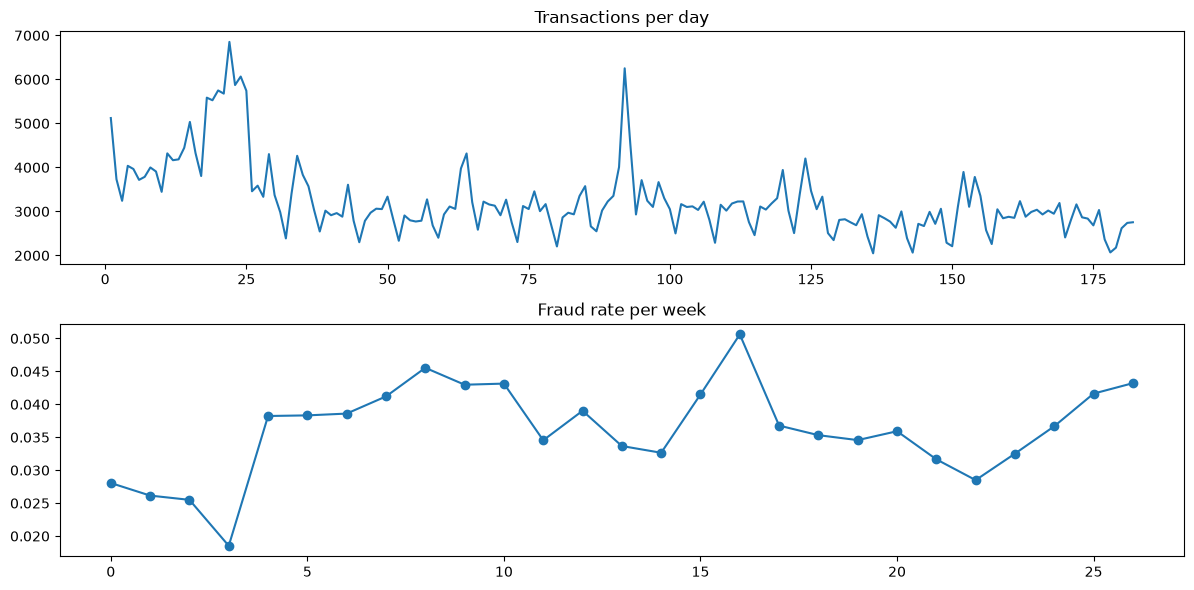

In [4]:
df["day"] = df["TransactionDT"] // 86400
print(f"Days covered: {df['day'].min()} to {df['day'].max()}")

daily = df.groupby("day").agg(n=("isFraud", "size"), fraud_rate=("isFraud", "mean"))
weekly = df.groupby(df["day"] // 7)["isFraud"].mean()

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=False)
ax[0].plot(daily.index, daily["n"]); ax[0].set_title("Transactions per day")
ax[1].plot(weekly.index, weekly.values, marker="o"); ax[1].set_title("Fraud rate per week")
plt.tight_layout(); plt.show()

In [23]:
import numpy as np

BASE = df["isFraud"].mean()

def fraud_by(col, top=None, data=None):
    data = df if data is None else data  # look up df at call time, not definition time
    key = data[col].astype("string").fillna("NaN")
    g = data.groupby(key)["isFraud"].agg(n="size", frauds="sum", rate="mean")
    g["share"] = g["n"] / len(data)
    g["lift"] = g["rate"] / BASE
    g = g.sort_values("n", ascending=False)
    return g.head(top).round(3) if top else g.round(3)

import gc; gc.collect()  # free the old DataFrame
print(f"Base fraud rate: {BASE:.4f}")

Base fraud rate: 0.0350


In [6]:
for col in ["ProductCD", "card4", "card6", "has_identity", "DeviceType"]:
    print(f"\n=== {col} ===")
    display(fraud_by(col))


=== ProductCD ===


,n,frauds,rate,share,lift
ProductCD,,,,,
W,439670,8969,0.020,0.745,0.583
C,68519,8008,0.117,0.116,3.340
R,37699,1426,0.038,0.064,1.081
H,33024,1574,0.048,0.056,1.362
S,11628,686,0.059,0.020,1.686



=== card4 ===


,n,frauds,rate,share,lift
card4,,,,,
visa,384767,13373,0.035,0.652,0.993
mastercard,189217,6496,0.034,0.320,0.981
american express,8328,239,0.029,0.014,0.820
discover,6651,514,0.077,0.011,2.209
NaN,1577,41,0.026,0.003,0.743



=== card6 ===


...


=== has_identity ===


C:\Users\ASUS\AppData\Local\Temp\ipykernel_12328\1995290759.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  key = data[col].astype("object").fillna("NaN")  # keep missing as its own level


,n,frauds,rate,share,lift
has_identity,,,,,
0,446307,9345,0.021,0.756,0.598
1,144233,11318,0.078,0.244,2.243



=== DeviceType ===


,n,frauds,rate,share,lift
DeviceType,,,,,
NaN,449730,9452,0.021,0.762,0.601
desktop,85165,5554,0.065,0.144,1.864
mobile,55645,5657,0.102,0.094,2.905


In [7]:
mcols = [f"M{i}" for i in range(1, 10)]
m_rates = pd.DataFrame({
    c: df.groupby(df[c].astype("object").fillna("NaN"))["isFraud"].mean()
    for c in mcols
}).T.round(3)
display(m_rates)

,F,M0,M1,M2,NaN,T
M1,0.000,NaN,NaN,NaN,0.053,0.020
M2,0.035,NaN,NaN,NaN,0.053,0.018
M3,0.030,NaN,NaN,NaN,0.053,0.017
M4,NaN,0.037,0.027,0.114,0.019,NaN
M5,0.027,NaN,NaN,NaN,0.037,0.038
M6,0.024,NaN,NaN,NaN,0.071,0.017
M7,0.019,NaN,NaN,NaN,0.046,0.022
M8,0.022,NaN,NaN,NaN,0.046,0.016
M9,0.030,NaN,NaN,NaN,0.046,0.018


In [8]:
print("=== P_emaildomain (top 15 by volume) ===")
display(fraud_by("P_emaildomain", top=15))
print("\n=== R_emaildomain (top 15 by volume) ===")
display(fraud_by("R_emaildomain", top=15))

print("\n=== Share of rows WITH a recipient email, per product ===")
display(pd.crosstab(df["ProductCD"], df["R_emaildomain"].notna(),
                    normalize="index").round(3))

=== P_emaildomain (top 15 by volume) ===


,n,frauds,rate,share,lift
P_emaildomain,,,,,
gmail.com,228355,9943,0.044,0.387,1.244
yahoo.com,100934,2297,0.023,0.171,0.650
NaN,94456,2790,0.030,0.160,0.844
hotmail.com,45250,2396,0.053,0.077,1.513
anonymous.com,36998,859,0.023,0.063,0.664
aol.com,28289,617,0.022,0.048,0.623
comcast.net,7888,246,0.031,0.013,0.891
icloud.com,6267,197,0.031,0.011,0.898
outlook.com,5096,482,0.095,0.009,2.703



=== R_emaildomain (top 15 by volume) ===


,n,frauds,rate,share,lift
R_emaildomain,,,,,
NaN,453249,9436,0.021,0.768,0.595
gmail.com,57147,6811,0.119,0.097,3.406
hotmail.com,27509,2140,0.078,0.047,2.223
anonymous.com,20529,598,0.029,0.035,0.833
yahoo.com,11842,610,0.052,0.020,1.472
aol.com,3701,129,0.035,0.006,0.996
outlook.com,2507,414,0.165,0.004,4.720
comcast.net,1812,21,0.012,0.003,0.331
yahoo.com.mx,1508,16,0.011,0.003,0.303



=== Share of rows WITH a recipient email, per product ===


R_emaildomain,False,True
ProductCD,,
C,0.031,0.969
H,0.328,0.672
R,0.000,1.000
S,0.051,0.949
W,1.000,0.000


            count    mean     std   min    25%   50%    75%       max
isFraud                                                              
0        569877.0  134.51  239.40  0.25  43.97  68.5  120.0  31937.39
1         20663.0  149.24  232.21  0.29  35.04  75.0  161.0   5191.00


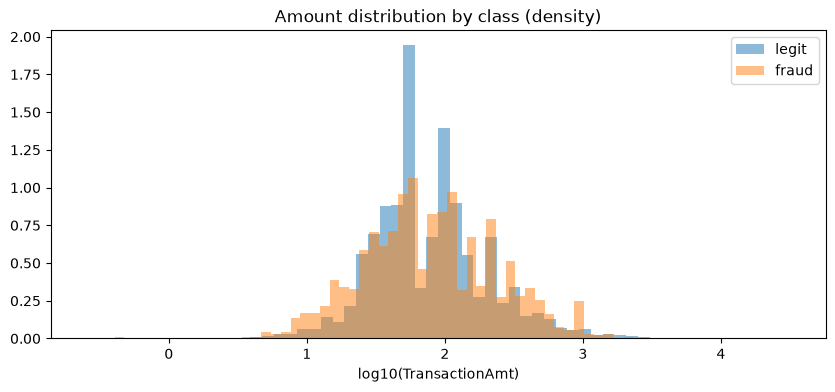


=== Fraud by number of decimals in amount ===


C:\Users\ASUS\AppData\Local\Temp\ipykernel_12328\1995290759.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  key = data[col].astype("object").fillna("NaN")  # keep missing as its own level


,n,frauds,rate,share,lift
amt_decimals,,,,,
0,305013,10882,0.036,0.516,1.020
2,200657,2092,0.010,0.340,0.298
3,61933,7259,0.117,0.105,3.350
1,22937,430,0.019,0.039,0.536


In [9]:
amt = df["TransactionAmt"]
print(df.groupby("isFraud")["TransactionAmt"].describe().round(2))

fig, ax = plt.subplots(figsize=(10, 4))
for label, name in [(0, "legit"), (1, "fraud")]:
    ax.hist(np.log10(amt[df["isFraud"] == label]), bins=60,
            density=True, alpha=0.5, label=name)
ax.set_xlabel("log10(TransactionAmt)"); ax.legend()
ax.set_title("Amount distribution by class (density)")
plt.show()

# Number of decimal places in the amount (0, 1, 2 or 3)
milli = np.round(amt * 1000).astype("int64")
df["amt_decimals"] = np.select(
    [milli % 10 != 0, milli % 100 != 0, milli % 1000 != 0], [3, 2, 1], default=0)
print("\n=== Fraud by number of decimals in amount ===")
display(fraud_by("amt_decimals"))

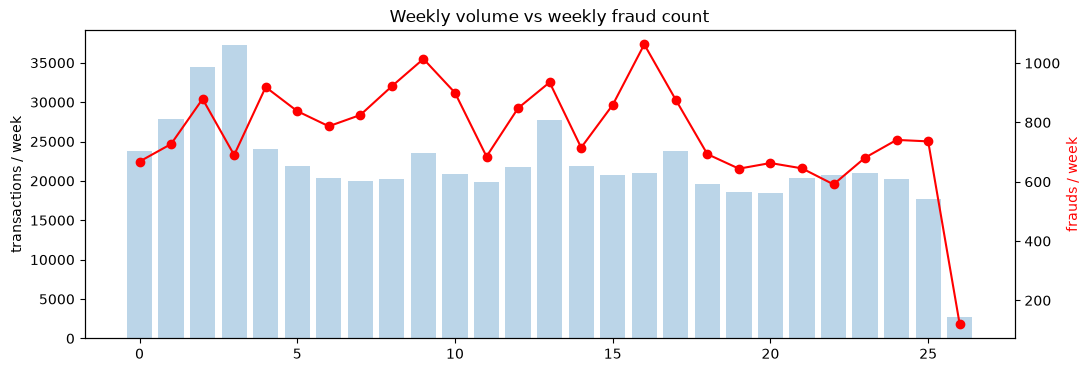

,n,frauds,rate
day,,,
0,23810,668,0.028055
1,27803,727,0.026148
2,34470,879,0.025500
3,37251,690,0.018523
4,24041,919,0.038226
5,21868,838,0.038321
6,20392,787,0.038594
7,20025,825,0.041199


In [10]:
wk = df.groupby(df["day"] // 7).agg(n=("isFraud", "size"), frauds=("isFraud", "sum"))
wk["rate"] = wk["frauds"] / wk["n"]

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.bar(wk.index, wk["n"], alpha=0.3, label="all transactions")
ax1.set_ylabel("transactions / week")
ax2 = ax1.twinx()
ax2.plot(wk.index, wk["frauds"], color="red", marker="o", label="frauds")
ax2.set_ylabel("frauds / week", color="red")
ax1.set_title("Weekly volume vs weekly fraud count"); plt.show()
display(wk.head(8))

In [11]:
print("=== 1. Fraud by number of decimals in amount ===")
display(fraud_by("amt_decimals"))

print("\n=== 2. Counts for some M flags ===")
for c in ["M1", "M4", "M5"]:
    print(df[c].value_counts(dropna=False), "\n")

print("=== 3. Identity vs fraud, within each product ===")
display(df.pivot_table(index="ProductCD", columns="has_identity",
                       values="isFraud", aggfunc=["size", "mean"]).round(3))

=== 1. Fraud by number of decimals in amount ===


C:\Users\ASUS\AppData\Local\Temp\ipykernel_12328\1995290759.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  key = data[col].astype("object").fillna("NaN")  # keep missing as its own level


,n,frauds,rate,share,lift
amt_decimals,,,,,
0,305013,10882,0.036,0.516,1.020
2,200657,2092,0.010,0.340,0.298
3,61933,7259,0.117,0.105,3.350
1,22937,430,0.019,0.039,0.536


C:\Users\ASUS\AppData\Local\Temp\ipykernel_12328\2036619877.py:9: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  display(df.pivot_table(index="ProductCD", columns="has_identity",



=== 2. Counts for some M flags ===
M1
T      319415
NaN    271100
F          25
Name: count, dtype: int64 

M4
NaN    281444
M0     196405
M2      59865
M1      52826
Name: count, dtype: int64 

M5
NaN    350482
F      132491
T      107567
Name: count, dtype: int64 

=== 3. Identity vs fraud, within each product ===


C:\Users\ASUS\AppData\Local\Temp\ipykernel_12328\2036619877.py:9: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  display(df.pivot_table(index="ProductCD", columns="has_identity",


size          mean       
has_identity       0      1      0      1
ProductCD                                
C               6327  62192  0.058  0.123
H                116  32908  0.026  0.048
R                151  37548  0.020  0.038
S                 43  11585  0.047  0.059
W             439670      0  0.020    NaN

In [12]:
vcols = [c for c in df.columns if re.fullmatch(r"V\d+", c)]
mask = df[vcols].isna()

# Give each column a fingerprint of WHICH rows are missing
sig = {c: hash(mask[c].values.tobytes()) for c in vcols}
blocks = {}
for c in vcols:
    blocks.setdefault(sig[c], []).append(c)
blocks = sorted(blocks.values(), key=lambda b: int(b[0][1:]))

print(f"{len(blocks)} row-level blocks (vs 15 by NaN count)")
for b in blocks:
    print(f"{len(b):3d} cols | NaN rows: {mask[b[0]].sum():>7,} | first: {b[0]}, last: {b[-1]}")
del mask

15 row-level blocks (vs 15 by NaN count)
 11 cols | NaN rows: 279,287 | first: V1, last: V11
 23 cols | NaN rows:  76,073 | first: V12, last: V34
 18 cols | NaN rows: 168,969 | first: V35, last: V52
 22 cols | NaN rows:  77,096 | first: V53, last: V74
 20 cols | NaN rows:  89,164 | first: V75, last: V94
 43 cols | NaN rows:     314 | first: V95, last: V137
 18 cols | NaN rows: 508,595 | first: V138, last: V163
 11 cols | NaN rows: 508,589 | first: V143, last: V166
 31 cols | NaN rows: 450,909 | first: V167, last: V216
 19 cols | NaN rows: 450,721 | first: V169, last: V210
 46 cols | NaN rows: 460,110 | first: V217, last: V278
 16 cols | NaN rows: 449,124 | first: V220, last: V272
 32 cols | NaN rows:      12 | first: V279, last: V321
 11 cols | NaN rows:   1,269 | first: V281, last: V315
 18 cols | NaN rows: 508,189 | first: V322, last: V339


#### Sort the columns by number of distinct values, richest first.
#### Keep the top one and remove every remaining column correlated with it above 0.75.
#### Repeat with whatever is left.

In [17]:
samp = df.sample(200_000, random_state=42)  # sample keeps it fast on 8 GB

def reduce_block(cols, data, thr=0.75):
    if len(cols) == 1:
        return cols
    corr = data[cols].corr().abs()
    # Prefer columns with more distinct values (more information)
    order = data[cols].nunique().sort_values(ascending=False).index.tolist()
    keep = []
    while order:
        c = order.pop(0)
        keep.append(c)
        order = [r for r in order if not corr.loc[c, r] > thr]  # drop near-duplicates of c
    return keep

v_keep = []
for b in blocks:
    k = reduce_block(b, samp)
    v_keep += k
    print(f"block starting {b[0]:>5} ({len(b):3d} cols) -> keep {len(k):2d}")
print(f"\nV columns: {len(vcols)} -> {len(v_keep)}")

block starting    V1 ( 11 cols) -> keep  6
block starting   V12 ( 23 cols) -> keep  8
block starting   V35 ( 18 cols) -> keep  8
block starting   V53 ( 22 cols) -> keep  9
block starting   V75 ( 20 cols) -> keep  9
block starting   V95 ( 43 cols) -> keep 20
block starting  V138 ( 18 cols) -> keep  6
block starting  V143 ( 11 cols) -> keep  3
block starting  V167 ( 31 cols) -> keep  7
block starting  V169 ( 19 cols) -> keep 12
block starting  V217 ( 46 cols) -> keep 17
block starting  V220 ( 16 cols) -> keep  6
block starting  V279 ( 32 cols) -> keep 14
block starting  V281 ( 11 cols) -> keep  8
block starting  V322 ( 18 cols) -> keep  5

V columns: 339 -> 138


In [14]:
import json
from pathlib import Path

out = Path("src/features/v_keep_v1.json")
out.parent.mkdir(parents=True, exist_ok=True)
out.write_text(json.dumps({
    "method": "NaN-block grouping + greedy |corr| > threshold, keep max nunique",
    "threshold": 0.75,
    "sample_rows": 200_000,
    "columns": sorted(v_keep, key=lambda c: int(c[1:])),
}, indent=2))
print("Saved", out)

Saved src\features\v_keep_v1.json


In [15]:
near_empty = miss[miss["na_rate"] > 0.95].sort_values("na_rate", ascending=False)
display(near_empty)

,na_rate,group
id_24,0.991962,id
id_25,0.991310,id
id_07,0.991271,id
id_08,0.991271,id
id_21,0.991264,id
id_26,0.991257,id
id_22,0.991247,id
id_23,0.991247,id
id_27,0.991247,id


In [18]:
rare_id = near_empty.index.tolist()
df["has_rare_id"] = df[rare_id].notna().any(axis=1).astype("int8")

# Compare within identity rows only (rare ids can't exist without identity)
display(fraud_by("has_rare_id", data=df[df["has_identity"] == 1]))

C:\Users\ASUS\AppData\Local\Temp\ipykernel_12328\1995290759.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  key = data[col].astype("object").fillna("NaN")  # keep missing as its own level


,n,frauds,rate,share,lift
has_rare_id,,,,,
0,139064,10892,0.078,0.964,2.238
1,5169,426,0.082,0.036,2.355


Example: card1=17188, addr1=299: 5,885 transactions


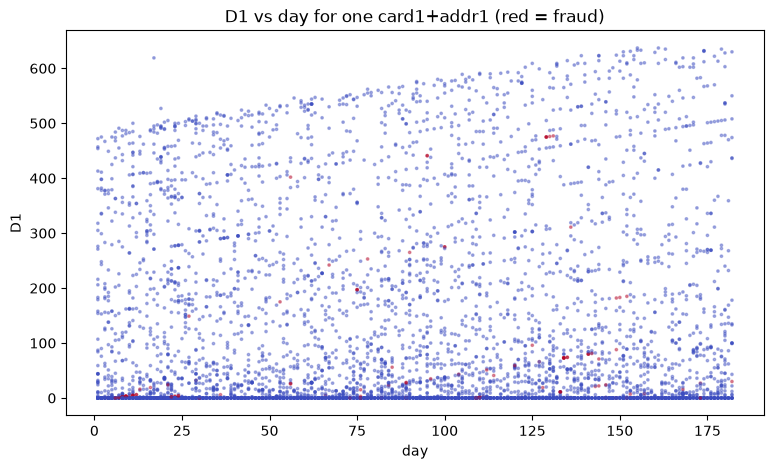

In [19]:
df = df.sort_values("TransactionDT").reset_index(drop=True)
df["D1n"] = df["day"] - df["D1"]  # "card start day"

c1, a1 = df.groupby(["card1", "addr1"]).size().idxmax()
ex = df[(df["card1"] == c1) & (df["addr1"] == a1)]
print(f"Example: card1={c1:.0f}, addr1={a1:.0f}: {len(ex):,} transactions")

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(ex["day"], ex["D1"], s=3, alpha=0.4, c=ex["isFraud"], cmap="coolwarm")
ax.set_xlabel("day"); ax.set_ylabel("D1")
ax.set_title("D1 vs day for one card1+addr1 (red = fraud)")
plt.show()

In [20]:
def s(col):
    return df[col].round().astype("Int64").astype("string").fillna("NA")

df["uid"] = s("card1") + "_" + s("addr1") + "_" + s("D1n")

n_per_uid = df.groupby("uid").size()
print(f"{df['uid'].nunique():,} uids for {len(df):,} transactions")
print(n_per_uid.describe().round(1))
print(f"uids with only 1 transaction: {(n_per_uid == 1).mean():.1%}")

217,850 uids for 590,540 transactions
count    217850.0
mean          2.7
std           5.5
min           1.0
25%           1.0
50%           1.0
75%           3.0
max        1414.0
dtype: float64
uids with only 1 transaction: 57.5%


In [21]:
df["k_card1"] = s("card1")
df["k_card_addr"] = s("card1") + "_" + s("addr1")

def purity(keycol):
    g = df.groupby(keycol)["isFraud"].agg(["size", "mean"])
    g = g[g["size"] >= 2]
    with_fraud = g[g["mean"] > 0]
    return pd.Series({
        "groups (>=2 txns)": len(g),
        "groups with any fraud": len(with_fraud),
        "of those: 100% fraud": (with_fraud["mean"] == 1).mean(),
        "of those: mixed": (with_fraud["mean"] < 1).mean(),
    })

display(pd.DataFrame({k: purity(k) for k in ["k_card1", "k_card_addr", "uid"]}).round(3))

,k_card1,k_card_addr,uid
groups (>=2 txns),10109.000,24222.00,92628.00
groups with any fraud,1594.000,2899.00,5102.00
of those: 100% fraud,0.036,0.08,0.39
of those: mixed,0.964,0.92,0.61


In [24]:
df["uid_txn_no"] = df.groupby("uid").cumcount() + 1  # 1 = this uid's first transaction so far
df["uid_txn_bucket"] = pd.cut(df["uid_txn_no"], [0, 1, 2, 5, 10, 50, np.inf],
                              labels=["1st", "2nd", "3-5", "6-10", "11-50", "51+"])
display(fraud_by("uid_txn_bucket"))

,n,frauds,rate,share,lift
uid_txn_bucket,,,,,
1st,217850,6044,0.028,0.369,0.793
3-5,125854,4517,0.036,0.213,1.026
2nd,92628,3099,0.033,0.157,0.956
6-10,77171,3057,0.040,0.131,1.132
11-50,70202,3548,0.051,0.119,1.444
51+,6835,398,0.058,0.012,1.664


In [25]:
display(n_per_uid.sort_values(ascending=False).head(10))
has_na = df["uid"].str.contains("NA")
print(f"Transactions with an incomplete uid (contains NA): {has_na.mean():.1%}")
print(f"Fraud rate, complete vs incomplete uid: "
      f"{df.loc[~has_na, 'isFraud'].mean():.3f} vs {df.loc[has_na, 'isFraud'].mean():.3f}")

uid
15775_330_129     1414
9500_126_-85       446
8900_231_-60       232
8528_387_-159      215
12616_NA_-491      211
12741_143_-202     196
7207_204_-465      191
15885_NA_22        174
13597_191_-48      148
4121_476_-8        142
dtype: int64

Transactions with an incomplete uid (contains NA): 11.3%
Fraud rate, complete vs incomplete uid: 0.025 vs 0.116
